# 04 · Modelo de riscos proporcionais de Cox

As curvas dos notebooks 02 e 03 mostram efeitos **univariados**: renda, moradia e juros andam juntos, então não dá para saber quanto de cada efeito é de cada variável. O Cox estima o efeito de cada covariável **mantendo as demais fixas**, na forma de um *hazard ratio* (HR):

$$h(t \mid x) = h_0(t)\,\exp(\beta^\top x) \quad\Rightarrow\quad \text{HR} = e^{\beta}$$

Um HR de 1,10 para juros significa que, a cada +1 p.p. de taxa, o risco de quebrar **em qualquer mês** (para quem ainda está ativo) fica 10% maior. O "em qualquer mês" é a hipótese de **riscos proporcionais**, testada na seção 5.

**Escolhas (ver `docs/decisoes.md`):**
- **Hazard específico do default:** o pré-pagamento entra como censura. É a leitura certa para *efeitos* (entre os contratos ativos, o que aumenta o risco de default?). Probabilidades acumuladas ficam para o Aalen-Johansen.
- **Base de ajuste:** todas as safras de 2007 a 2015 (cerca de 884 mil contratos, sem amostragem). As safras de 2016 a 2018 ficam guardadas para a validação fora do tempo (notebook 05).
- **Grade fora do modelo:** a taxa de juros é definida a partir do sub-grade. Com os dois no modelo, o HR dos juros viraria "+1 p.p. dentro do mesmo grade".
- **Prazo como covariável:** a razão de hazards 60m/36m bruta é estável (notebook 03), e o prazo é um dos efeitos pedidos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from lifelines import CoxPHFitter
from lifelines.statistics import proportional_hazard_test
from lifelines.utils import concordance_index

from time_to_default.cox import (COVARIATES, TRAIN_VINTAGES, design_matrix, fit_by_period, fit_cox,
                                 hr_table, period_hr_table)
from time_to_default.features import PROCESSED_PATH
from time_to_default.plotting import BLUE, GRAY, ORANGE, SERIES, savefig, set_style
from time_to_default.reporting import update_metrics

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_colwidth", 120)

data = pd.read_parquet(PROCESSED_PATH)
train = data[data["vintage"].isin(TRAIN_VINTAGES)]
X = design_matrix(train)
del data
print(f"{len(X):,} contratos de treino ({len(train) - len(X)} sem uso do rotativo descartados), "
      f"{int(X['default'].sum()):,} defaults")

883,528 contratos de treino (460 sem uso do rotativo descartados), 151,111 defaults


## 1. Covariáveis e unidades

Cada covariável foi transformada para que o HR tenha uma unidade de leitura direta.

In [2]:
units = pd.DataFrame(COVARIATES, index=["variável", "unidade do HR"]).T
units["média no treino"] = X[list(COVARIATES)].mean()
units

,variável,unidade do HR,média no treino
int_rate,taxa de juros,+1 p.p. ao ano,13.240
term_60,prazo de 60 meses,60 vs. 36 meses,0.301
dti,comprometimento com dívidas (DTI),+10 p.p. da renda,1.814
pti,comprometimento com a parcela (PTI),+1 p.p. da renda,7.978
log2_income,renda anual,renda 2× maior,15.979
fico,score FICO,+20 pontos,34.849
home_rent,mora de aluguel,vs. imóvel financiado,0.401
home_own,imóvel próprio quitado,vs. imóvel financiado,0.099
emp_years,tempo de emprego,+1 ano,5.710
emp_missing,tempo de emprego não informado,vs. informado,0.051


## 2. O modelo e a tabela de hazard ratios interpretada

In [3]:
cph = fit_cox(X)
c_train = concordance_index(X["duration"], -cph.predict_partial_hazard(X), X["default"])
print(f"C-index (treino): {c_train:.3f}  |  log-verossimilhança parcial: {cph.log_likelihood_:,.0f}")

hrs = hr_table(cph).sort_values("HR", ascending=False)
hrs[["variável", "unidade", "HR", "IC 95% inf", "IC 95% sup", "leitura"]]

C-index (treino): 0.672  |  log-verossimilhança parcial: -1,965,493


,variável,unidade,HR,IC 95% inf,IC 95% sup,leitura
covariate,,,,,,
home_rent,mora de aluguel,vs. imóvel financiado,1.206,1.192,1.220,"Mora de aluguel (vs. imóvel financiado) aumenta o risco de default em 20,6%"
emp_missing,tempo de emprego não informado,vs. informado,1.149,1.123,1.175,"Tempo de emprego não informado (vs. informado) aumenta o risco de default em 14,9%"
dti,comprometimento com dívidas (DTI),+10 p.p. da renda,1.136,1.129,1.144,"Cada +10 p.p. da renda (comprometimento com dívidas (DTI)) aumenta o risco de default em 13,6%"
verified,renda verificada,vs. não verificada,1.102,1.087,1.116,"Renda verificada (vs. não verificada) aumenta o risco de default em 10,2%"
int_rate,taxa de juros,+1 p.p. ao ano,1.097,1.095,1.099,"Cada +1 p.p. ao ano (taxa de juros) aumenta o risco de default em 9,7%"
inquiries,consultas de crédito em 6 meses,+1 consulta,1.085,1.080,1.091,"Cada +1 consulta (consultas de crédito em 6 meses) aumenta o risco de default em 8,5%"
home_own,imóvel próprio quitado,vs. imóvel financiado,1.078,1.059,1.097,"Imóvel próprio quitado (vs. imóvel financiado) aumenta o risco de default em 7,8%"
pti,comprometimento com a parcela (PTI),+1 p.p. da renda,1.017,1.015,1.018,"Cada +1 p.p. da renda (comprometimento com a parcela (PTI)) aumenta o risco de default em 1,7%"
term_60,prazo de 60 meses,60 vs. 36 meses,1.015,1.003,1.028,"Prazo de 60 meses (60 vs. 36 meses) aumenta o risco de default em 1,5%"


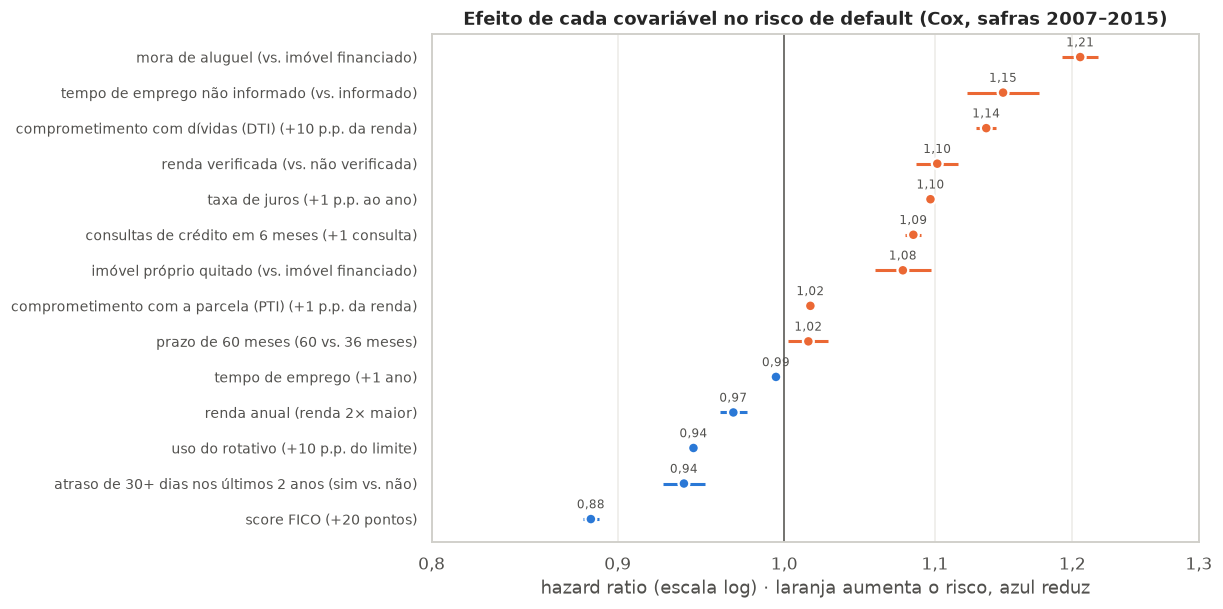

In [4]:
fig, ax = plt.subplots(figsize=(9, 6))
plot = hrs.sort_values("HR")
y = np.arange(len(plot))
colors = [ORANGE if hr > 1 else BLUE for hr in plot["HR"]]
ax.hlines(y, plot["IC 95% inf"], plot["IC 95% sup"], color=colors, lw=2)
ax.scatter(plot["HR"], y, color=colors, s=50, zorder=3, edgecolor="white", linewidth=1.5)
ax.axvline(1, color=GRAY, lw=1)
for yi, (hr, unit) in enumerate(zip(plot["HR"], plot["unidade"])):
    ax.annotate(f"{hr:.2f}".replace(".", ","), (hr, yi), xytext=(0, 7), textcoords="offset points",
                ha="center", fontsize=8, color=GRAY)
ax.set_yticks(y, [f"{v} ({u})" for v, u in zip(plot["variável"], plot["unidade"])], fontsize=9)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ",")))
ax.xaxis.set_minor_formatter(mtick.NullFormatter())
ax.set_xticks([0.8, 0.9, 1.0, 1.1, 1.2, 1.3])
ax.set_xlabel("hazard ratio (escala log) · laranja aumenta o risco, azul reduz")
ax.set_title("Efeito de cada covariável no risco de default (Cox, safras 2007–2015)")
ax.grid(axis="y", visible=False)
savefig(fig, "cox_forest")
plt.show()

## 3. Sinais contraintuitivos: o score e o preço já usam essa informação

Três covariáveis aparecem com sinal inesperado ou muito menor no modelo completo: **uso do rotativo** e **atraso anterior** passam a *reduzir* o risco, e **renda verificada** perde a maior parte do efeito. A comparação abaixo mostra de onde isso vem:
- **univariado:** só a covariável;
- **sem juros:** todas as covariáveis, menos a taxa de juros;
- **sem juros e sem FICO:** todas, menos as duas;
- **completo:** todas.

In [5]:
univariate = pd.Series({c: fit_cox(X, [c]).hazard_ratios_[c] for c in COVARIATES})
no_rate = fit_cox(X, [c for c in COVARIATES if c != "int_rate"]).hazard_ratios_
no_rate_fico = fit_cox(X, [c for c in COVARIATES if c not in ("int_rate", "fico")]).hazard_ratios_
compare = pd.DataFrame({
    "variável": [COVARIATES[c][0] for c in COVARIATES],
    "univariado": univariate,
    "sem juros": no_rate.reindex(list(COVARIATES)),
    "sem juros e sem FICO": no_rate_fico.reindex(list(COVARIATES)),
    "completo": cph.hazard_ratios_.reindex(list(COVARIATES)),
})
compare

,variável,univariado,sem juros,sem juros e sem FICO,completo
int_rate,taxa de juros,1.120,NaN,NaN,1.097
term_60,prazo de 60 meses,1.448,1.464,1.451,1.015
dti,comprometimento com dívidas (DTI),1.245,1.145,1.133,1.136
pti,comprometimento com a parcela (PTI),1.053,1.038,1.033,1.017
log2_income,renda anual,0.807,0.948,0.880,0.968
fico,score FICO,0.796,0.798,NaN,0.885
home_rent,mora de aluguel,1.307,1.253,1.330,1.206
home_own,imóvel próprio quitado,1.039,1.099,1.131,1.078
emp_years,tempo de emprego,0.985,0.995,0.995,0.995
emp_missing,tempo de emprego não informado,1.312,1.139,1.131,1.149


**Leitura:**
- **Atraso anterior e uso do rotativo** só voltam ao sinal esperado quando o modelo perde **juros e FICO juntos** (o atraso anterior vai de 0,94 para cerca de 1,12). O score FICO é calculado em boa parte com o histórico de atrasos e o uso de crédito, e a LendingClub definiu o preço em cima dele. Comparando dois tomadores **com o mesmo score e a mesma taxa**, quem tem um atraso anterior precisou ser melhor em outros aspectos para chegar àquele score. Por isso o efeito condicional fica abaixo de 1.
- **A renda verificada** cai de 1,45 (univariado) para 1,17 com os demais controles, e para 1,10 com os juros. Os contratos com renda verificada pagam juros maiores (13,9% contra 11,7% a.a. no treino), o que é coerente com a LendingClub pedir comprovação mais aos perfis que pareciam mais arriscados. Os +10% que sobram são seleção que o modelo não explica, não um efeito causal da verificação.

Isso não quer dizer que atrasar "faz bem". Quer dizer que, **dados o score e o preço**, a informação já foi usada. Para "quem é mais arriscado?", vale o HR univariado. Para "o que o score e o preço **não** capturam?", vale o modelo completo.

## 4. Forma funcional da taxa de juros

O Cox supõe que cada +1 p.p. tem o mesmo efeito, seja de 6% para 7% ou de 25% para 26%. Para checar, a taxa é trocada por faixas (decis) e o HR de cada faixa é comparado com a reta do modelo linear.

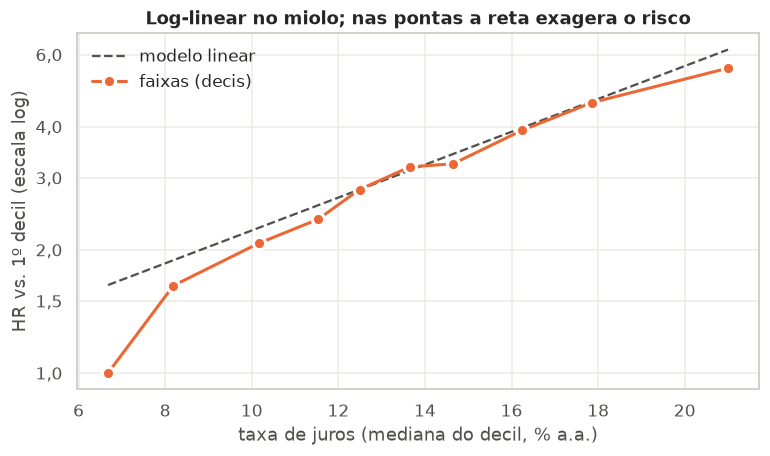

,taxa mediana,HR faixas,HR linear
0,6.680,1.000,1.640
1,8.190,1.635,1.886
2,10.160,2.075,2.263
3,11.530,2.374,2.569
4,12.490,2.808,2.808
5,13.650,3.189,3.126
6,14.650,3.246,3.429
7,16.240,3.916,3.972
8,17.860,4.580,4.615
9,21.000,5.558,6.170


In [6]:
deciles = pd.qcut(X["int_rate"], 10)
Xd = X.drop(columns="int_rate").join(pd.get_dummies(deciles, prefix="dec", drop_first=True, dtype=float))
dec_cols = [c for c in Xd.columns if c.startswith("dec_")]
# os decis não estão em COVARIATES, então o ajuste vai direto pelo lifelines
cph_dec = CoxPHFitter().fit(Xd[[c for c in COVARIATES if c != "int_rate"] + dec_cols + ["duration", "default"]],
                            "duration", "default")
medians = X.groupby(deciles, observed=True)["int_rate"].median().to_numpy()
hr_dec = np.r_[1.0, cph_dec.hazard_ratios_[dec_cols].to_numpy()]
# a reta do modelo linear é ancorada no decil do meio para comparar a inclinação
mid = 4
hr_lin = hr_dec[mid] * np.exp(cph.params_["int_rate"] * (medians - medians[mid]))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(medians, hr_lin, color=GRAY, ls="--", lw=1.5, label="modelo linear")
ax.plot(medians, hr_dec, "o-", color=ORANGE, ms=8, mec="white", mew=2, label="faixas (decis)")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ",")))
ax.yaxis.set_minor_formatter(mtick.NullFormatter())
ax.set_yticks([1, 1.5, 2, 3, 4, 6])
ax.set_xlabel("taxa de juros (mediana do decil, % a.a.)")
ax.set_ylabel("HR vs. 1º decil (escala log)")
ax.set_title("Log-linear no miolo; nas pontas a reta exagera o risco")
ax.legend(frameon=False)
savefig(fig, "cox_int_rate_form")
plt.show()
pd.DataFrame({"taxa mediana": medians, "HR faixas": hr_dec, "HR linear": hr_lin}).round(3)

**Leitura:** do 2º ao 9º decil (taxas de ~8% a 18%), os decis acompanham a reta do modelo linear (cerca de +10% de risco por p.p.). Nas pontas, a reta exagera. O 1º decil (até 7,7%, com 99,7% dos contratos no grade A) tem risco bem menor do que ela prevê, e o 10º decil (acima de 19%) um pouco menor. Então o HR de juros vale para o miolo da distribuição, e os contratos de juros mais baixos são ainda mais seguros do que o modelo diz. Uma alternativa seria uma spline nos juros, que deixei de fora para manter a leitura "por p.p." pedida no projeto.

## 5. Riscos proporcionais: o efeito é o mesmo em todo o contrato?

**5a. Teste formal (resíduos de Schoenfeld).** Calcular os resíduos na base inteira custa memória e tempo que crescem com o quadrado do número de contratos: 100 mil levam 12 s, e 884 mil levariam uns 15 minutos perto do limite de RAM. O teste usa uma **subamostra fixa de 100 mil contratos** (semente 0), que é reproduzível e já tem poder de sobra. Com essa amostra, mesmo desvios pequenos dão p-valor baixo, então a estatística serve mais para ordenar *quais* covariáveis desviam mais.

In [7]:
sub = X.sample(100_000, random_state=0)
cph_sub = fit_cox(sub)
ph = proportional_hazard_test(cph_sub, sub[list(COVARIATES) + ["duration", "default"]], time_transform="rank")
ph_table = ph.summary[["test_statistic", "p"]].rename(columns={"test_statistic": "qui²", "p": "p-valor"})
ph_table.insert(0, "variável", [COVARIATES[c][0] for c in ph_table.index])
ph_table.sort_values("qui²", ascending=False)

,variável,qui²,p-valor
int_rate,taxa de juros,152.999,0.000
term_60,prazo de 60 meses,31.253,0.000
fico,score FICO,30.055,0.000
emp_years,tempo de emprego,14.146,0.000
inquiries,consultas de crédito em 6 meses,7.549,0.006
dti,comprometimento com dívidas (DTI),7.435,0.006
pti,comprometimento com a parcela (PTI),5.917,0.015
emp_missing,tempo de emprego não informado,2.984,0.084
revol_util,uso do rotativo,2.047,0.152
home_own,imóvel próprio quitado,1.968,0.161


**5b. HR por fase do contrato (base inteira).** Um Cox é ajustado para cada fase, só com os contratos ainda em risco no começo dela (entrada atrasada). Isso equivale a um Cox com coeficientes que mudam em degraus ao longo do tempo, e mostra *como* o efeito muda, não só *se* muda.

In [8]:
by_period = fit_by_period(X)
period_hrs = period_hr_table(by_period)
period_view = period_hrs.copy()
period_view.insert(0, "variável", [COVARIATES[c][0] for c in period_view.index])
period_view["modelo único"] = cph.hazard_ratios_.reindex(period_view.index)
period_view

,variável,1–6,7–12,13–24,25–36,37–60,modelo único
covariate,,,,,,,
int_rate,taxa de juros,1.164,1.124,1.090,1.069,1.058,1.097
term_60,prazo de 60 meses,0.786,0.930,1.021,1.142,NaN,1.015
dti,comprometimento com dívidas (DTI),1.150,1.195,1.150,1.090,1.021,1.136
pti,comprometimento com a parcela (PTI),0.995,1.015,1.023,1.017,1.013,1.017
log2_income,renda anual,0.940,0.954,0.980,0.982,0.950,0.968
fico,score FICO,1.006,0.917,0.862,0.855,0.873,0.885
home_rent,mora de aluguel,1.368,1.214,1.188,1.187,1.166,1.206
home_own,imóvel próprio quitado,1.242,1.090,1.060,1.059,1.005,1.078
emp_years,tempo de emprego,0.975,0.984,0.997,1.004,1.006,0.995


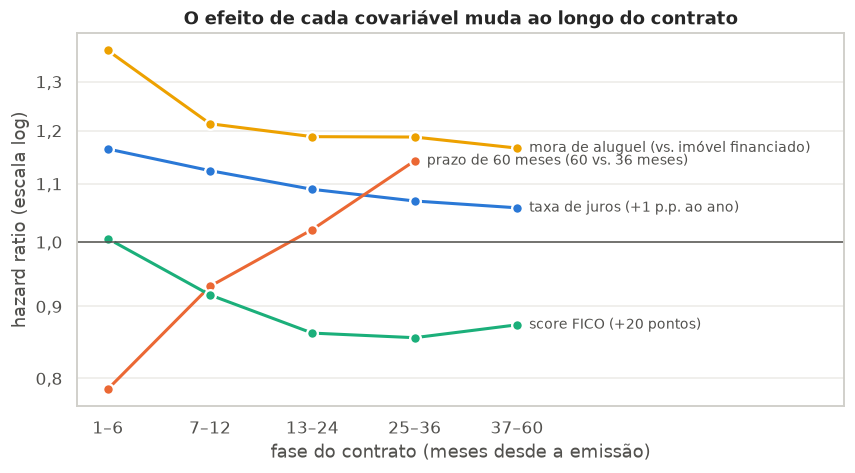

In [9]:
show = ["int_rate", "term_60", "fico", "home_rent"]
fig, ax = plt.subplots(figsize=(9, 4.4))
x = np.arange(len(period_hrs.columns))
for c, color in zip(show, SERIES):
    ax.plot(x, period_hrs.loc[c], "o-", color=color, ms=7, mec="white", mew=1.5, label=COVARIATES[c][0])
    last = period_hrs.loc[c].last_valid_index()
    xi = list(period_hrs.columns).index(last)
    ax.annotate(f"{COVARIATES[c][0]} ({COVARIATES[c][1]})", (xi, period_hrs.loc[c, last]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=9, color=GRAY)
ax.axhline(1, color=GRAY, lw=1)
ax.set_xticks(x, list(period_hrs.columns))
ax.set_xlabel("fase do contrato (meses desde a emissão)")
ax.set_xlim(-0.3, len(x) + 2.2)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ",")))
ax.yaxis.set_minor_formatter(mtick.NullFormatter())
ax.set_yticks([0.8, 0.9, 1.0, 1.1, 1.2, 1.3])
ax.set_ylabel("hazard ratio (escala log)")
ax.set_title("O efeito de cada covariável muda ao longo do contrato")
ax.grid(axis="x", visible=False)
savefig(fig, "cox_hr_by_period")
plt.show()

## Leitura final

**Tabela para o portfólio** (modelo único, safras 2007–2015; o HR é a média ponderada ao longo do contrato):

In [10]:
portfolio = hrs[["leitura", "HR", "IC 95% inf", "IC 95% sup"]].copy()
portfolio["HR nos meses 1–6"] = period_hrs["1–6"]
portfolio["HR nos meses 25–36"] = period_hrs["25–36"]
portfolio.loc[["int_rate", "dti", "home_rent", "inquiries", "fico", "log2_income", "emp_missing",
               "pti", "term_60", "home_own", "verified", "revol_util", "past_delinq", "emp_years"]]

,leitura,HR,IC 95% inf,IC 95% sup,HR nos meses 1–6,HR nos meses 25–36
covariate,,,,,,
int_rate,"Cada +1 p.p. ao ano (taxa de juros) aumenta o risco de default em 9,7%",1.097,1.095,1.099,1.164,1.069
dti,"Cada +10 p.p. da renda (comprometimento com dívidas (DTI)) aumenta o risco de default em 13,6%",1.136,1.129,1.144,1.150,1.090
home_rent,"Mora de aluguel (vs. imóvel financiado) aumenta o risco de default em 20,6%",1.206,1.192,1.220,1.368,1.187
inquiries,"Cada +1 consulta (consultas de crédito em 6 meses) aumenta o risco de default em 8,5%",1.085,1.080,1.091,1.112,1.071
fico,"Cada +20 pontos (score FICO) reduz o risco de default em 11,5%",0.885,0.881,0.889,1.006,0.855
log2_income,"Cada renda 2× maior (renda anual) reduz o risco de default em 3,2%",0.968,0.960,0.976,0.940,0.982
emp_missing,"Tempo de emprego não informado (vs. informado) aumenta o risco de default em 14,9%",1.149,1.123,1.175,0.986,1.260
pti,"Cada +1 p.p. da renda (comprometimento com a parcela (PTI)) aumenta o risco de default em 1,7%",1.017,1.015,1.018,0.995,1.017
term_60,"Prazo de 60 meses (60 vs. 36 meses) aumenta o risco de default em 1,5%",1.015,1.003,1.028,0.786,1.142


1. **Juros:** cada +1 p.p. de taxa aumenta o risco relativo de default em cerca de **10%** no modelo completo, e em 12% sem controles. O efeito é bem mais forte no começo do contrato (cerca de +16% por p.p. nos 6 primeiros meses) e cai para uns +6% depois do 3º ano. Juros altos sinalizam quebra **precoce**.
2. **O prazo, sozinho, quase não explica nada.** O HR bruto de 60m vs. 36m é cerca de 1,45, mas, controlando juros, comprometimento e score, cai para cerca de 1,0. O risco maior dos contratos longos vem de quem os contrata e do preço cobrado. Além disso, o efeito ajustado *inverte*: os contratos de 60 meses quebram menos no início (parcela menor) e mais no fim.
3. **Comprometimento de renda:** +10 p.p. de DTI aumenta o risco em cerca de 14%. O PTI (só a parcela deste empréstimo) acrescenta pouco depois de controlar DTI e juros.
4. **Patrimônio importa:** quem mora de aluguel tem cerca de 21% mais risco que quem tem imóvel financiado, com os demais fatores iguais.
5. **O FICO não ajuda no começo:** o efeito protetor só aparece depois do 6º mês. As quebras precoces são mal previstas pelo score de bureau.
6. **Riscos proporcionais não valem à risca.** Os efeitos de juros, prazo e FICO mudam ao longo do contrato. O modelo único continua útil como **resumo** (o HR é uma média ponderada no tempo), mas para *prever* a probabilidade de default por horizonte o modelo por fase deve ser melhor. O notebook 05 compara os dois fora do tempo.
7. **C-index de treino de cerca de 0,67:** o modelo ordena bem o risco, sem ser excelente. Isso é esperado para dados de concessão sem comportamento de pagamento.

In [11]:
update_metrics("cox", {
    "train_vintages": [min(TRAIN_VINTAGES), max(TRAIN_VINTAGES)],
    "train_loans": int(len(X)),
    "train_defaults": int(X["default"].sum()),
    "c_index_train": round(float(c_train), 4),
    "hazard_ratios": {c: {"HR": round(float(r["HR"]), 4), "low": round(float(r["IC 95% inf"]), 4),
                          "high": round(float(r["IC 95% sup"]), 4), "reading": r["leitura"]}
                      for c, r in hrs.iterrows()},
    "univariate_hr": univariate.round(4).to_dict(),
    "hr_by_period": {c: period_hrs.loc[c].round(4).dropna().to_dict() for c in period_hrs.index},
    "schoenfeld_chi2_100k": ph_table["qui²"].round(2).to_dict(),
})

{'data': {'raw_loans': 2260668,
  'loans': 2064692,
  'snapshot': '2019-03',
  'observation_end': '2018-11',
  'funnel': [{'etapa': 'base bruta', 'contratos': 2260668, 'removidos': 0},
   {'etapa': 'dentro da política de crédito',
    'contratos': 2257919,
    'removidos': 2749},
   {'etapa': 'pedido individual', 'contratos': 2137209, 'removidos': 120710},
   {'etapa': 'moradia própria, financiada ou aluguel',
    'contratos': 2136024,
    'removidos': 1185},
   {'etapa': 'renda anual positiva', 'contratos': 2136024, 'removidos': 0},
   {'etapa': 'emitido antes do fim da observação',
    'contratos': 2064692,
    'removidos': 71332}],
  'event_share': {'censurado': 0.5047,
   'pré-pagamento': 0.3715,
   'default': 0.1239},
  'term_36_share': 0.72},
 'kaplan_meier': {'term_36': {'cif_default_12m': 0.0487,
   'cif_default_term': 0.1444,
   'naive_km_default_term': 0.206,
   'cif_prepay_term': 0.5623},
  'term_60': {'cif_default_12m': 0.07,
   'cif_default_term': 0.27,
   'naive_km_defaul